# CORUNA SCRAPPING

In [3]:
from urllib.robotparser import RobotFileParser
import requests

# Descargar robots.txt usando un User-Agent propio
url_robots = "https://en.wikipedia.org/robots.txt"

respuesta = requests.get(
    url_robots,
    headers={"User-Agent": "curso-sbd-demo/1.0"},
)

print("Estado HTTP:", respuesta.status_code)

# Leer las reglas con RobotFileParser
rp = RobotFileParser()
rp.parse(respuesta.text.splitlines())

# Comprobar la página
pagina = "https://en.wikipedia.org/wiki/List_of_municipalities_in_A_Coru%C3%B1a"

print("¿Se permite descargarla?:", rp.can_fetch("curso-sbd-demo/1.0", pagina))

Estado HTTP: 200
¿Se permite descargarla?: True


In [4]:
import time
from io import StringIO
from pathlib import Path
from urllib.parse import urljoin
from urllib.robotparser import RobotFileParser

import pandas as pd
import requests
from bs4 import BeautifulSoup

BASE = "https://en.wikipedia.org/wiki/List_of_municipalities_in_A_Coru%C3%B1a"
CABECEIRAS = {"User-Agent": "curso-sbd-demo/1.0 (docente@exemplo.gal)"}
PAUSA = 1.0                      # segundos entre peticións

RAW = Path("../datos/raw/html")
CLEAN = Path("../datos/clean")
RAW.mkdir(parents=True, exist_ok=True)
CLEAN.mkdir(parents=True, exist_ok=True)

## 1. Antes de nada: robots.txt

O ficheiro `robots.txt` indica que partes do sitio non queren que se percorran automaticamente e, ás veces, canto esperar entre peticións. Non é unha lei, pero é o primeiro sinal do que o propietario considera aceptable.

In [10]:
print(requests.get(urljoin(BASE, "robots.txt"), headers=CABECEIRAS, timeout=10).text)

robots = RobotFileParser(urljoin(BASE, "robots.txt"))
robots.read()
for ruta in ["index.html", "poxas/2025-03-03.html", "admin/usuarios.html"]:
    print(f"{ruta:28} permitido? {robots.can_fetch(CABECEIRAS['User-Agent'], urljoin(BASE, ruta))}")
print("Crawl-delay:", robots.crawl_delay(CABECEIRAS["User-Agent"]))

User-agent: *
Disallow: /admin/ # non mires en admin
Crawl-delay: 1 # esperate 1 segundo

index.html                   permitido? True
poxas/2025-03-03.html        permitido? True
admin/usuarios.html          permitido? False
Crawl-delay: 1


## 2. Unha petición HTTP

`requests.get()` fai o mesmo que o navegador cando escribimos unha URL: envía unha petición e recibe unha resposta con **código de estado**, **cabeceiras** e **corpo**.

In [5]:
resposta = requests.get(BASE, headers=CABECEIRAS, timeout=10) # esperar 10 segundos como máximo
print("Código de estado:", resposta.status_code) # EL BASE devolve 200 se todo foi ben
print("Content-Type    :", resposta.headers.get("Content-Type")) # CABECEIRAS devolve text/html; charset=utf-8
print("Codificación    :", resposta.encoding)
print()
print(resposta.text[:600])

Código de estado: 200
Content-Type    : text/html; charset=UTF-8
Codificación    : UTF-8

<!DOCTYPE html>
<html class="client-nojs vector-feature-language-in-header-enabled vector-feature-language-in-main-menu-disabled vector-feature-language-in-main-page-header-disabled vector-feature-page-tools-pinned-disabled vector-feature-toc-pinned-clientpref-1 vector-feature-main-menu-pinned-disabled vector-feature-limited-width-clientpref-1 vector-feature-limited-width-content-enabled vector-feature-custom-font-size-clientpref-1 vector-feature-appearance-pinned-clientpref-1 skin-theme-clientpref-day vector-sticky-header-enabled vector-toc-available skin-thumbsize-clientpref-standard skin-un


Fíxate no texto: `Â·` e `PÃ¡xina` en vez de `·` e `Páxina`. É o problema de codificación do Tema 2. O servidor non indica o *charset* na cabeceira `Content-Type`, e `requests` supón ISO-8859-1 (Latin-1). Pero a páxina está en UTF-8, como di a súa etiqueta `<meta charset="utf-8">`.

Dúas solucións: indicar a codificación correcta ou, mellor, pasarlle a BeautifulSoup os **bytes** (`resposta.content`), porque el le a etiqueta `<meta>` e decodifica ben.

In [6]:
resposta.encoding = "utf-8"
for lina in resposta.text.splitlines():
    if "<title>" in lina or "Páxina" in lina:
        print(lina)

<title>List of municipalities in A Coruña - Wikipedia</title>


Que pasa se pedimos unha páxina que non existe? `raise_for_status()` converte os códigos de erro (4xx, 5xx) nunha excepción, para que o programa non siga coma se nada.

In [7]:
erro = requests.get(urljoin(BASE, "poxas/2030-01-01.html"), headers=CABECEIRAS, timeout=10)
print("Código:", erro.status_code)
try:
    erro.raise_for_status()
except requests.HTTPError as e:
    print("HTTPError:", e)

Código: 404
HTTPError: 404 Client Error: Not Found for url: https://en.wikipedia.org/wiki/Poxas/2030-01-01.html


## 3. Do HTML á árbore: BeautifulSoup

BeautifulSoup converte o texto HTML nunha árbore (o DOM) que podemos percorrer e na que podemos buscar.

In [11]:
sopa = BeautifulSoup(resposta.content, "html.parser")

print(sopa.title.get_text())
print(sopa.find("h1").get_text())

List of municipalities in A Coruña - Wikipedia
List of municipalities in A Coruña


In [12]:
for tabla in sopa.find_all("table")[:3]:
    print(tabla.get("class"))

['wikitable', 'sortable']
['nowraplinks', 'mw-collapsible', 'autocollapse', 'navbox-inner']


In [15]:
tabla = sopa.find("table", class_="wikitable")

print(tabla.get_text()[:200])


Name
Population (2024)[20]

Abegondo
5,578

Ames
32,812

Aranga
1,799

Ares
6,156

Arteixo
34,038

Arzúa
5,887

A Baña
3,291

Bergondo
6,986

Betanzos
13,261

Boimorto
1.801

Boiro
19,018

Boqueixón



In [16]:
for th in tabla.find_all("th"):
    print(th.get_text(strip=True))

Name
Population (2024)[20]


In [17]:
for fila in tabla.find_all("tr")[:5]:
    celdas = fila.find_all(["th", "td"])
    print([celda.get_text(" ", strip=True) for celda in celdas])

['Name', 'Population (2024) [ 20 ]']
['Abegondo', '5,578']
['Ames', '32,812']
['Aranga', '1,799']
['Ares', '6,156']


In [18]:
sopa = BeautifulSoup(resposta.content, "html.parser")

print("Título:", sopa.title.get_text())
print("h1:", sopa.find("h1").get_text())

tabla = sopa.find("table", class_="wikitable")

print("¿Tabla encontrada?:", tabla is not None)

Título: List of municipalities in A Coruña - Wikipedia
h1: List of municipalities in A Coruña
¿Tabla encontrada?: True


In [19]:
ligazons = tabla.find_all("a")

print("Ligazóns:", len(ligazons))

for a in ligazons[:3]:
    print(a.get_text(strip=True), "→", a.get("href"))

Ligazóns: 94
[20] → #cite_note-20
Abegondo → https://en.wikipedia.org/wiki/Abegondo
Ames → https://en.wikipedia.org/wiki/Ames,_A_Coruña


un parser html. O contido html e analizado e devolvese unha arbora DOM (xetarquico). Chamaselle sopa.

Sopa ten toda a noza pax web nese formato. 

Podemos facer sobsultas sobre sopa. "Sola, dame todas as taboas", etc.

As ligazóns son **relativas** (`poxas/2025-03-03.html`). Para descargalas necesitamos a URL completa: `urljoin` combínaas coa URL da páxina onde están.

Os **selectores CSS** (`select`, `select_one`) son unha alternativa máis compacta a `find`: `ul#dias a` significa "as etiquetas `a` dentro da lista con id `dias`".

In [20]:
tabla = sopa.find("table", class_="wikitable")

for th in tabla.find_all("th"):
    print(th.get_text(" ", strip=True))

Name
Population (2024) [ 20 ]


In [21]:
datos = []

for fila in tabla.find_all("tr")[1:]:
    celdas = fila.find_all("td")

    if len(celdas) >= 2:
        concello = celdas[0].get_text(" ", strip=True)
        poboacion = celdas[1].get_text(" ", strip=True)

        datos.append({
            "Concello": concello,
            "Poboacion": poboacion
        })

df = pd.DataFrame(datos)

display(df.head())

,Concello,Poboacion
0,Abegondo,"5,578"
1,Ames,"32,812"
2,Aranga,"1,799"
3,Ares,"6,156"
4,Arteixo,"34,038"


In [15]:
urls = [urljoin(resposta.url, a["href"]) for a in sopa.select("ul#dias a")]
urls[:3]

['http://localhost:8000/poxas/2025-03-03.html',
 'http://localhost:8000/poxas/2025-03-04.html',
 'http://localhost:8000/poxas/2025-03-05.html']

## 4. Paxinación: seguir a ligazón "Seguinte"

O índice ocupa varias páxinas. Seguimos a ligazón `a.seguinte` ata que xa non exista.

In [16]:
def ligazons_poxas(url_inicio):
    """Percorre o índice paxinado e devolve as URL de todas as poxas."""
    urls, url = [], url_inicio
    while url:
        r = requests.get(url, headers=CABECEIRAS, timeout=10)
        r.raise_for_status()
        s = BeautifulSoup(r.content, "html.parser")
        urls += [urljoin(r.url, a["href"]) for a in s.select("ul#dias a")]
        seguinte = s.select_one("a.seguinte")
        url = urljoin(r.url, seguinte["href"]) if seguinte else None
        print("Lida", r.url, "→", len(urls), "ligazóns acumuladas")
        time.sleep(PAUSA)
    return urls

urls_poxas = ligazons_poxas(BASE)

Lida http://localhost:8000/ → 10 ligazóns acumuladas
Lida http://localhost:8000/paxina2.html → 20 ligazóns acumuladas


## 5. Descargar e gardar o HTML orixinal

Gardamos cada páxina **tal como chega** en `raw/`. Se despois descubrimos un erro no código que extrae os datos, repetimos esa parte sen volver a descargar nada: menos carga para o servidor e máis rapidez para nós. Se o ficheiro xa existe, non se descarga.

In [17]:
def descargar(url, destino):
    if destino.exists():
        return "xa existía"
    r = requests.get(url, headers=CABECEIRAS, timeout=10)
    r.raise_for_status()
    destino.write_bytes(r.content)
    time.sleep(PAUSA)
    return "descargado"

for url in urls_poxas:
    ficheiro = RAW / url.rsplit("/", 1)[-1]
    print(ficheiro.name, descargar(url, ficheiro))

2025-03-03.html descargado
2025-03-04.html descargado
2025-03-05.html descargado
2025-03-06.html descargado
2025-03-07.html descargado
2025-03-10.html descargado
2025-03-11.html descargado
2025-03-12.html descargado
2025-03-13.html descargado
2025-03-14.html descargado
2025-03-17.html descargado
2025-03-18.html descargado
2025-03-19.html descargado
2025-03-20.html descargado
2025-03-21.html descargado
2025-03-24.html descargado
2025-03-25.html descargado
2025-03-26.html descargado
2025-03-27.html descargado
2025-03-28.html descargado


## 6. Extraer os datos dunha táboa

Primeiro cunha soa páxina. Percorremos as filas (`tr`) do `tbody` e, en cada unha, as celas (`td`).

In [18]:
exemplo = sorted(RAW.glob("*.html"))[0]
sopa = BeautifulSoup(exemplo.read_bytes(), "html.parser")
taboa = sopa.select_one("table.poxa")

cabeceiras = [th.get_text(strip=True) for th in taboa.select("thead th")]
print(cabeceiras)
for tr in taboa.select("tbody tr")[:3]:
    print([td.get_text(strip=True) for td in tr.find_all("td")])

['Especie', 'Kg vendidos', 'Prezo medio (€/kg)', 'Prezo máximo (€/kg)']
['Xurelo', '2.287,0', '1,76', '2,11']
['Choco', '546,5', '6,53', '8,15']
['Polbo', '1.017,6', '12,22', '13,09']


Convertémolo nunha función que devolve unha lista de dicionarios, un por fila. Gardamos tamén a ligazón á ficha da especie (o atributo `href`).

In [19]:
def extraer_poxa(ficheiro):
    sopa = BeautifulSoup(ficheiro.read_bytes(), "html.parser")
    data = ficheiro.stem                     # o nome do ficheiro é a data
    filas = []
    for tr in sopa.select("table.poxa tbody tr"):
        celas = tr.find_all("td")
        filas.append({
            "data": data,
            "especie": celas[0].get_text(strip=True),
            "ficha": celas[0].find("a")["href"],
            "kg": celas[1].get_text(strip=True),
            "prezo_medio": celas[2].get_text(strip=True),
            "prezo_maximo": celas[3].get_text(strip=True),
        })
    return filas

filas = [f for ficheiro in sorted(RAW.glob("*.html")) for f in extraer_poxa(ficheiro)]
poxas = pd.DataFrame(filas)
print(poxas.shape)
poxas.head()

(167, 6)


,data,especie,ficha,kg,prezo_medio,prezo_maximo
0,2025-03-03,Xurelo,../especies/xurelo.html,"2.287,0","1,76","2,11"
1,2025-03-03,Choco,../especies/choco.html,"546,5","6,53","8,15"
2,2025-03-03,Polbo,../especies/polbo.html,"1.017,6","12,22","13,09"
3,2025-03-03,Ameixa fina,../especies/ameixa-fina.html,"76,9","28,78","35,83"
4,2025-03-03,Rape,../especies/rape.html,"349,3","14,40","17,99"


In [20]:
poxas.info()

<class 'pandas.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   data          167 non-null    str  
 1   especie       167 non-null    str  
 2   ficha         167 non-null    str  
 3   kg            167 non-null    str  
 4   prezo_medio   167 non-null    str  
 5   prezo_maximo  167 non-null    str  
dtypes: str(6)
memory usage: 8.0 KB


## 7. Limpar

Todo chega como texto e en formato español (`1.234,5`), e as especies sen poxa aparecen cun guión longo (`—`).

In [21]:
def numero_es(serie):
    return pd.to_numeric(
        serie.replace("—", None).str.replace(".", "", regex=False).str.replace(",", ".", regex=False),
        errors="coerce",
    )

for col in ["kg", "prezo_medio", "prezo_maximo"]:
    poxas[col] = numero_es(poxas[col])
poxas["data"] = pd.to_datetime(poxas["data"], format="%Y-%m-%d")
print(poxas.dtypes)
print("Especies sen poxa algún día:", poxas["kg"].isna().sum())

data            datetime64[us]
especie                    str
ficha                      str
kg                     float64
prezo_medio            float64
prezo_maximo           float64
dtype: object
Especies sen poxa algún día: 9


Comprobación: a suma dos kg de cada día debe coincidir co total que mostra a propia páxina (`p.resumo`). Validar co que di a fonte é unha boa práctica sempre que sexa posible.

In [22]:
def total_paxina(ficheiro):
    texto = BeautifulSoup(ficheiro.read_bytes(), "html.parser").select_one("p.resumo strong").get_text()
    return float(texto.replace(" kg", "").replace(".", "").replace(",", "."))

totais = pd.Series({pd.Timestamp(f.stem): total_paxina(f) for f in RAW.glob("*.html")}).sort_index()
suma = poxas.groupby("data")["kg"].sum()
print("Coinciden todos os días?", ((totais - suma).abs() < 0.05).all())

Coinciden todos os días? True


## 8. Atallo: `pd.read_html`

Se os datos están nunha `<table>` ben formada, pandas pode lela directamente. Devolve **unha lista** de DataFrames, unha por táboa da páxina.

In [25]:
taboas = pd.read_html(StringIO(exemplo.read_text(encoding="utf-8")), decimal=",", thousands=".", na_values=["—"])
print("Táboas atopadas:", len(taboas))
taboas[0].head()

Táboas atopadas: 1


,Especie,Kg vendidos,Prezo medio (€/kg),Prezo máximo (€/kg)
0,Xurelo,2287.0,1.76,2.11
1,Choco,546.5,6.53,8.15
2,Polbo,1017.6,12.22,13.09
3,Ameixa fina,76.9,28.78,35.83
4,Rape,349.3,14.40,17.99


In [24]:
!pip install lxml

  Using cached lxml-6.1.3-cp314-cp314-manylinux_2_26_x86_64.manylinux_2_28_x86_64.whl.metadata (3.3 kB)
Using cached lxml-6.1.3-cp314-cp314-manylinux_2_26_x86_64.manylinux_2_28_x86_64.whl (5.2 MB)


É moito máis rápido de escribir, pero **perde a información que non é texto da cela** (por exemplo, a ligazón `href` á ficha da especie) e non serve cando os datos non están nunha táboa. BeautifulSoup dá control total; `read_html` é un atallo para táboas sinxelas.

## 9. Seguir ligazóns: o nome científico de cada especie

In [26]:
fichas = {}
for ruta in poxas["ficha"].unique():
    url = urljoin(BASE + "poxas/", ruta)
    r = requests.get(url, headers=CABECEIRAS, timeout=10)
    r.raise_for_status()
    fichas[ruta] = BeautifulSoup(r.content, "html.parser").select_one("p.cientifico em").get_text()
    time.sleep(PAUSA)

poxas["nome_cientifico"] = poxas["ficha"].map(fichas)
poxas[["especie", "nome_cientifico"]].drop_duplicates().sort_values("especie")

,especie,nome_cientifico
3,Ameixa fina,Ruditapes decussatus
5,Berberecho,Cerastoderma edule
1,Choco,Sepia officinalis
8,Lirio,Micromesistius poutassou
10,Pescada,Merluccius merluccius
2,Polbo,Octopus vulgaris
4,Rape,Lophius piscatorius
6,Rodaballo,Scophthalmus maximus
7,Sardiña,Sardina pilchardus
0,Xurelo,Trachurus trachurus


## 10. Gardar e unha primeira análise

In [27]:
poxas.drop(columns="ficha").to_csv(CLEAN / "poxas_porto_bravo.csv", index=False, encoding="utf-8")

resumo = (poxas.groupby("especie")
               .agg(dias=("kg", "count"), kg_total=("kg", "sum"), prezo_medio=("prezo_medio", "mean"))
               .sort_values("prezo_medio", ascending=False)
               .round(2))
resumo

,dias,kg_total,prezo_medio
especie,,,
Ameixa fina,16,2088.3,32.86
Rodaballo,17,3768.7,18.10
Rape,15,5744.8,13.27
Polbo,14,11537.2,11.82
Pescada,15,21125.9,8.21
Choco,15,7739.1,7.81
Berberecho,17,13467.6,6.39
Sardiña,16,66537.5,2.74
Xurelo,14,48367.0,2.06


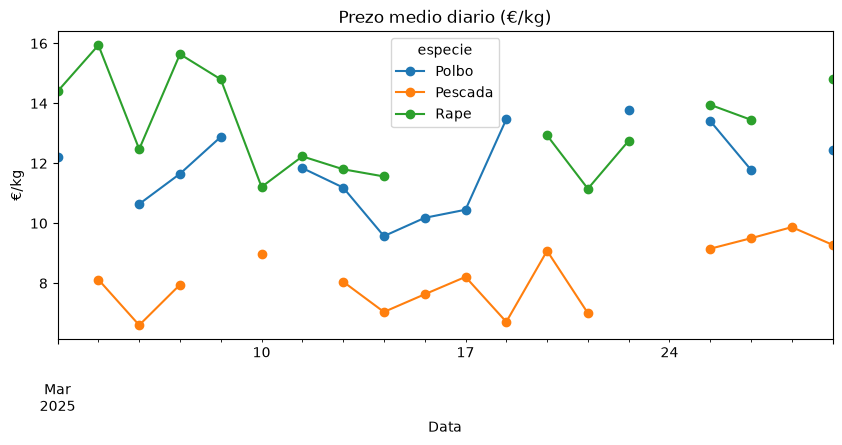

In [28]:
ax = (poxas.pivot_table(index="data", columns="especie", values="prezo_medio")[["Polbo", "Pescada", "Rape"]]
           .plot(marker="o", figsize=(10, 4), title="Prezo medio diario (€/kg)"))
ax.set_ylabel("€/kg")
ax.set_xlabel("Data");

## Resumo

1. Revisar `robots.txt` e as condicións de uso.
2. Inspeccionar o HTML no navegador antes de programar.
3. Descargar con `requests`, identificándose e con pausas, e **gardar o HTML en `raw/`**.
4. Extraer con BeautifulSoup (ou `read_html` se é unha táboa sinxela).
5. Limpar, validar coa propia fonte e gardar en `clean/`.